In [1]:
#Assignment 2: Testing data analysis skills with pandas, numpy, and matplotlib. Use the dataset from the zip file.
#Total points: 24

#You are allowed to seek help from your classmates; however, it should be your own work.
#You can not copy or paste their work. If you seek help, you need to acknowledge it in your submission.
#You will submit the commented and outputs-printed Jupyter Notebook file

#Remove all unnecessary code and outputs. 


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix #You may or may not need

In [4]:
df = pd.read_csv("/Users/Mayo/Downloads/Data Analysis Assignment Used Phones/used_device_data.csv")

In [5]:
# Question 1: Report any data limitations

print("Dataset shape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nDataset summary:")
print(df.info())

Dataset shape:
(3454, 15)

Missing values:
device_brand               0
os                         0
screen_size                0
4g                         0
5g                         0
rear_camera_mp           179
front_camera_mp            2
internal_memory            4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

Number of duplicate rows:
0

Data types:
device_brand                 str
os                           str
screen_size              float64
4g                           str
5g                           str
rear_camera_mp           float64
front_camera_mp          float64
internal_memory          float64
ram                      float64
battery                  float64
weight                   float64
release_year               int64
days_used                  int64
normalized_used_price    float64
norma

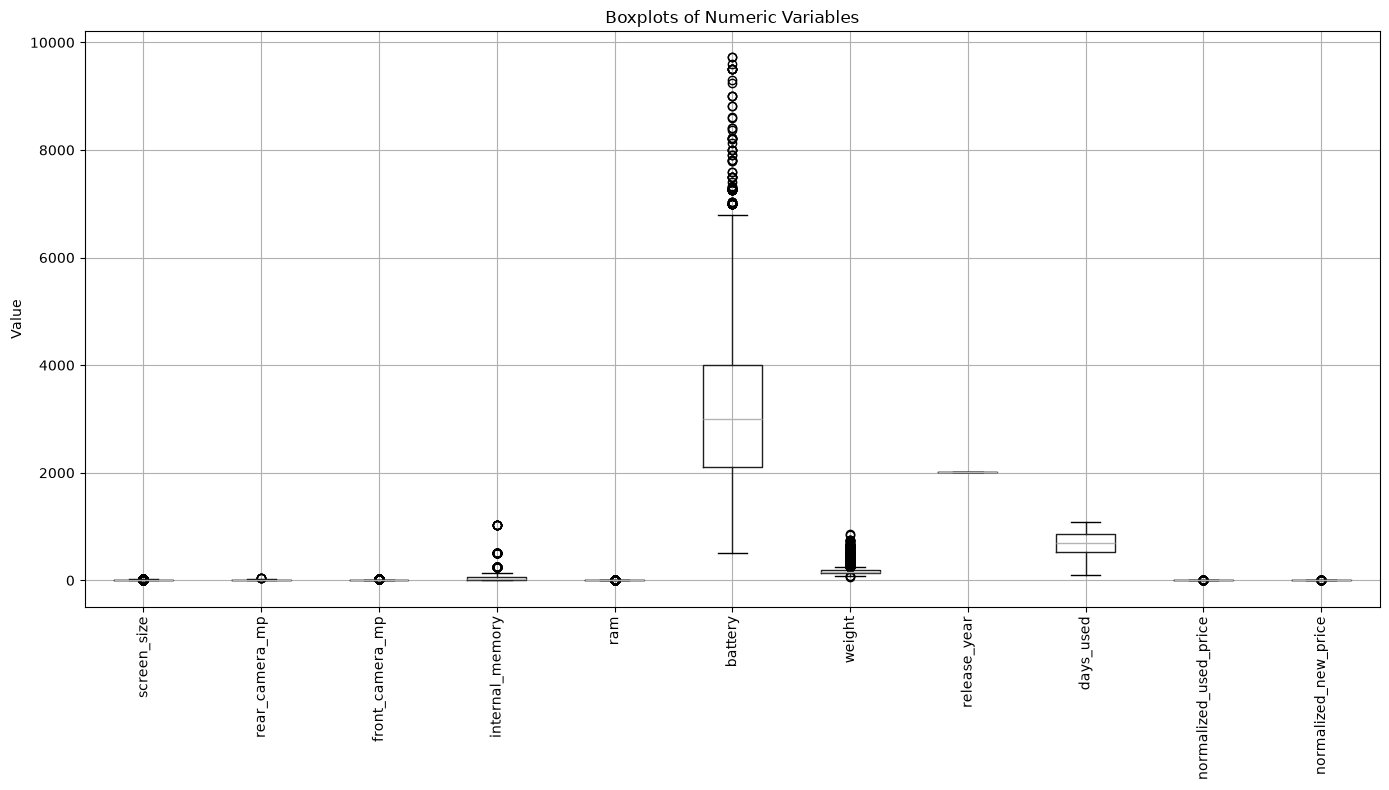

In [6]:
# Question 2: Visualize outliers

numeric_columns = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(14, 8))
df[numeric_columns].boxplot(rot=90)

plt.title("Boxplots of Numeric Variables")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

In [7]:
# Question 3: Create device_age

df["device_age"] = 2026 - df["release_year"]

mean_device_age = df["device_age"].mean()

print("Mean device age:", mean_device_age)

Mean device age: 10.034742327735959


In [8]:
# Question 4a

days_used = df["days_used"].to_numpy()

average_days = np.mean(days_used)
minimum_days = np.min(days_used)
maximum_days = np.max(days_used)

print("Average days used:", average_days)
print("Minimum days used:", minimum_days)
print("Maximum days used:", maximum_days)

Average days used: 674.8697162709901
Minimum days used: 91
Maximum days used: 1094


In [9]:
# Question 4b

used_price = df["normalized_used_price"].to_numpy()

std_used_price = np.std(used_price)
variance_used_price = np.var(used_price)

print("Standard deviation:", std_used_price)
print("Variance:", variance_used_price)

Standard deviation: 0.5888283607206609
Variance: 0.3467188383889808


In [10]:
# Question 4c

new_price_percentiles = np.percentile(
    df["normalized_new_price"],
    [25, 50, 75]
)

used_price_percentiles = np.percentile(
    df["normalized_used_price"],
    [25, 50, 75]
)

print("Normalized New Price Percentiles:")
print("25th percentile:", new_price_percentiles[0])
print("50th percentile:", new_price_percentiles[1])
print("75th percentile:", new_price_percentiles[2])

print("\nNormalized Used Price Percentiles:")
print("25th percentile:", used_price_percentiles[0])
print("50th percentile:", used_price_percentiles[1])
print("75th percentile:", used_price_percentiles[2])

Normalized New Price Percentiles:
25th percentile: 4.7903418435
50th percentile: 5.2458918494999995
75th percentile: 5.67371825

Normalized Used Price Percentiles:
25th percentile: 4.0339308525
50th percentile: 4.405132623
75th percentile: 4.7557000075


In [11]:
# Question 4d

count_below_45 = np.sum(df["normalized_used_price"] < 4.5)

print("Number of devices with normalized used price below 4.5:", count_below_45)

Number of devices with normalized used price below 4.5: 2001


In [12]:
# Question 5

sample_df = df.sample(n=500, random_state=42)

sample_average = np.mean(sample_df["normalized_used_price"])

print("Average normalized used price of sample:", sample_average)

Average normalized used price of sample: 4.397000235396


In [13]:
# Question 7a

used_price_mean = np.mean(df["normalized_used_price"])
used_price_std = np.std(df["normalized_used_price"])

df["used_price_zscore"] = (
    df["normalized_used_price"] - used_price_mean
) / used_price_std

outliers = df[np.abs(df["used_price_zscore"]) > 3]

print("Number of outliers:", len(outliers))

Number of outliers: 35


In [14]:
# Question 7b

variables = ["days_used", "internal_memory", "weight"]

print("Whole Dataset Means:")
print(df[variables].mean())

print("\nOutlier Means:")
print(outliers[variables].mean())

Whole Dataset Means:
days_used          674.869716
internal_memory     54.573099
weight             182.751871
dtype: float64

Outlier Means:
days_used          679.971429
internal_memory    177.489697
weight             140.662857
dtype: float64


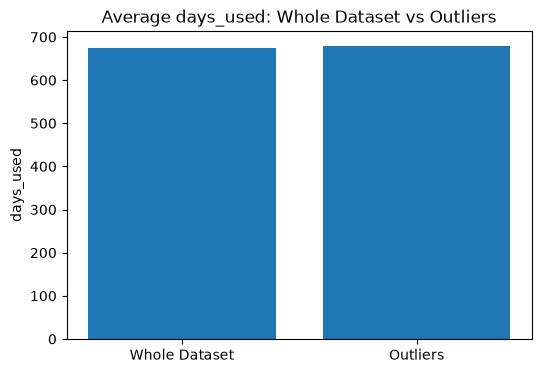

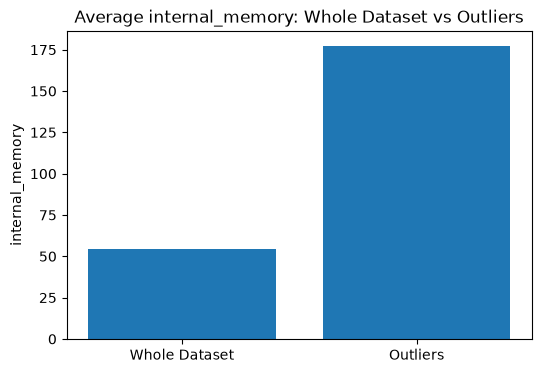

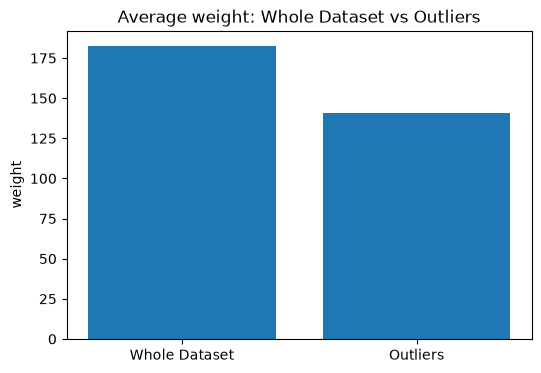

In [16]:
# Question 7c

variables = ["days_used", "internal_memory", "weight"]

for variable in variables:
    values = [
        df[variable].mean(),
        outliers[variable].mean()
    ]

    plt.figure(figsize=(6, 4))
    plt.bar(["Whole Dataset", "Outliers"], values)

    plt.title(f"Average {variable}: Whole Dataset vs Outliers")
    plt.ylabel(variable)

    plt.show()

In [ ]:
#Continue Case 2 with stattsmodels

In [17]:
# Question 8

import statsmodels.api as sm

# Create dummy variable for 5G
df["5g_yes"] = np.where(df["5g"] == "Yes", 1, 0)

# Select variables
regression_data = df[
    [
        "internal_memory",
        "battery",
        "weight",
        "days_used",
        "5g_yes",
        "normalized_used_price"
    ]
].dropna()

# Independent variables
X = regression_data[
    ["internal_memory", "battery", "weight", "days_used", "5g_yes"]
]

# Dependent variable
y = regression_data["normalized_used_price"]

# Add intercept
X = sm.add_constant(X)

# Create regression model
model = sm.OLS(y, X).fit()

# Print results
print(model.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.405
Model:                               OLS   Adj. R-squared:                  0.404
Method:                    Least Squares   F-statistic:                     582.9
Date:                   Tue, 29 Sep 2026   Prob (F-statistic):               0.00
Time:                           23:27:09   Log-Likelihood:                -2147.5
No. Observations:                   3437   AIC:                             4305.
Df Residuals:                       3432   BIC:                             4336.
Df Model:                              4                                         
Covariance Type:               nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const       

/opt/anaconda3/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])


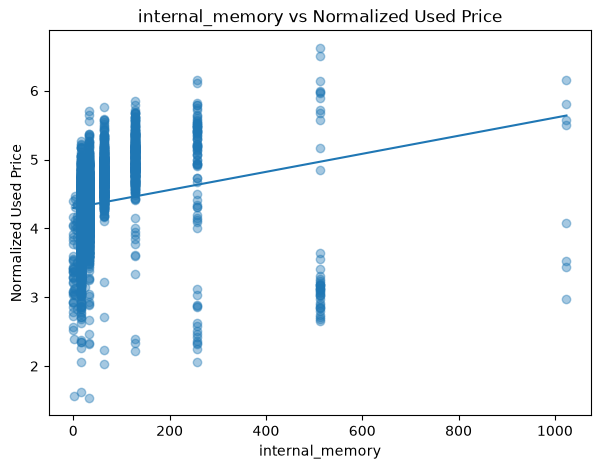

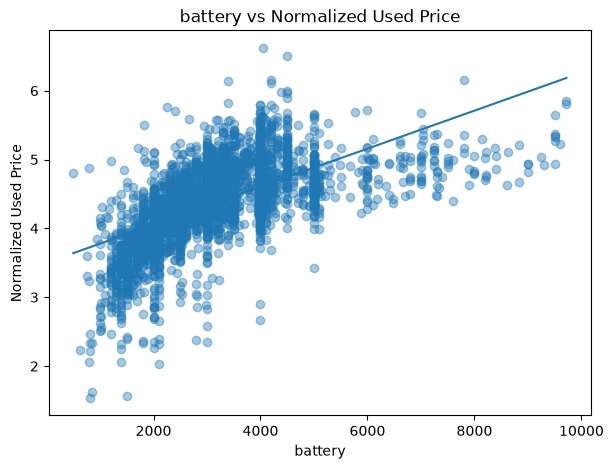

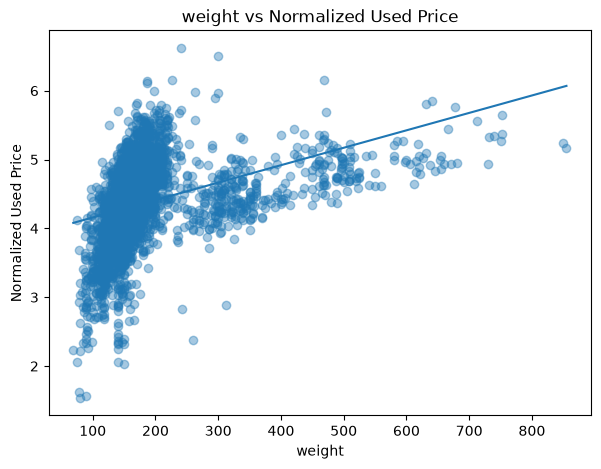

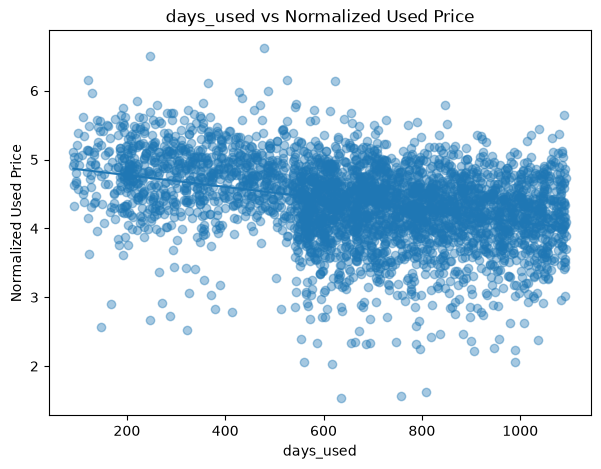

/opt/anaconda3/lib/python3.14/site-packages/numpy/lib/_polynomial_impl.py:674: RuntimeWarning: invalid value encountered in divide
  lhs /= scale


LinAlgError: SVD did not converge in Linear Least Squares

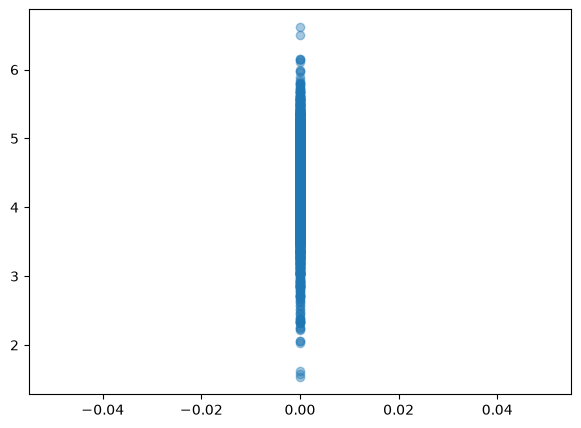

In [18]:
# Question 9

predictors = [
    "internal_memory",
    "battery",
    "weight",
    "days_used",
    "5g_yes"
]

for predictor in predictors:
    
    plot_data = regression_data[[predictor, "normalized_used_price"]].dropna()

    x = plot_data[predictor]
    y = plot_data["normalized_used_price"]

    plt.figure(figsize=(7, 5))

    # Scatterplot
    plt.scatter(x, y, alpha=0.4)

    # Regression line
    slope, intercept = np.polyfit(x, y, 1)

    regression_line = slope * x + intercept

    # Sort values so regression line displays properly
    order = np.argsort(x)

    plt.plot(
        x.iloc[order],
        regression_line.iloc[order]
    )

    plt.xlabel(predictor)
    plt.ylabel("Normalized Used Price")
    plt.title(f"{predictor} vs Normalized Used Price")

    plt.show()